# Movie Recommendation System
## Machine Learning Individual Project
Third Year - Computer Science and Engineering

This notebook documents the machine learning workflow of the project.

## 1. Import Libraries

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Dataset Loading

In [16]:
df = pd.read_csv("../Dataset/selected_movies.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (47, 6)


,movie_id,title,genre,description,language,content
0,1,Avatar,Sci-Fi,An alien world filled with action and adventure,English,Sci-Fi An alien world filled with action and a...
1,3,The Avengers,Action,Superheroes unite to save the world,English,Action Superheroes unite to save the world
2,4,Interstellar,Sci-Fi,A journey through space and time,English,Sci-Fi A journey through space and time
3,5,The Imitation Game,Drama,A mathematician works to solve a complex warti...,English,Drama A mathematician works to solve a complex...
4,6,Iron Man,Action,A genius builds a powerful suit,English,Action A genius builds a powerful suit


In [4]:
import pandas as pd

original_df = pd.read_csv("../movies.csv")
df = pd.read_csv("../Dataset/selected_movies.csv")

print("Original dataset:", len(original_df))
print("Notebook dataset:", len(df))

missing_movies = original_df[
    ~original_df["title"].isin(df["title"])
]

print("\nMissing movie:")
display(missing_movies[["movie_id", "title", "genre", "language"]])

Original dataset: 48
Notebook dataset: 47

Missing movie:


,movie_id,title,genre,language
33,39,The Secret Life of Mitty,Adventure,English


In [5]:
# Find the missing movie
missing_rows = original_df[
    ~original_df["title"].isin(df["title"])
].copy()

# Create the ML content feature
missing_rows["content"] = (
    missing_rows["genre"].fillna("") + " " +
    missing_rows["description"].fillna("")
)

# Select the same columns as the notebook dataset
missing_rows = missing_rows[
    ["movie_id", "title", "genre", "description", "language", "content"]
]

# Add the missing movie
df = pd.concat([df, missing_rows], ignore_index=True)

# Save the updated dataset
df.to_csv("../Dataset/selected_movies.csv", index=False)

print("Updated dataset shape:", df.shape)
print("Total movies:", len(df))

Updated dataset shape: (48, 6)
Total movies: 48


## 3. Data Information and Preprocessing

In [ ]:
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   movie_id     48 non-null     int64
 1   title        48 non-null     str  
 2   genre        48 non-null     str  
 3   description  48 non-null     str  
 4   language     48 non-null     str  
 5   content      48 non-null     str  
dtypes: int64(1), str(5)
memory usage: 7.8 KB

Missing values:
movie_id       0
title          0
genre          0
description    0
language       0
content        0
dtype: int64

Duplicate rows: 0


## 4. Exploratory Data Analysis

genre
Action              7
Drama               6
Animation           6
Comedy              6
Sci-Fi              5
Adventure           3
Horror              3
Fantasy             2
Romance             2
Mystery             2
Biography           2
Historical          1
Thriller            1
Sports              1
Historical Drama    1
Name: count, dtype: int64


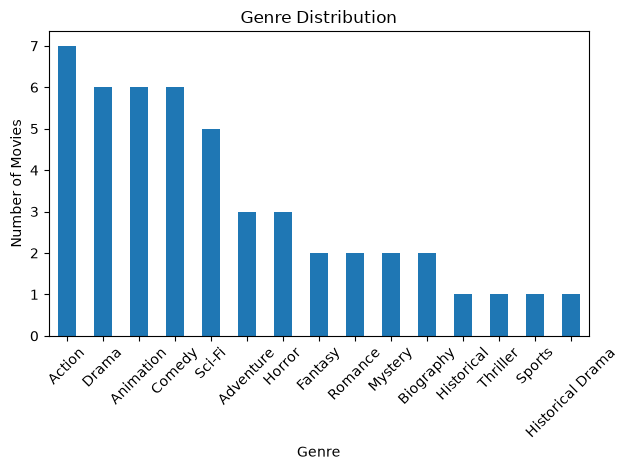

In [10]:
print(df["genre"].value_counts())

df["genre"].value_counts().plot(
    kind="bar",
    title="Genre Distribution"
)

plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Feature Selection

In [11]:
X = df["content"].fillna("")

print("Selected feature: content (genre + description)")
print("Total records:", len(X))
print("Feature shape:", X.shape)

Selected feature: content (genre + description)
Total records: 48
Feature shape: (48,)


## 6. Train-Test Split

In [12]:
X_train, X_test = train_test_split(
    X, test_size=0.2, random_state=42
)

print("Total records:", len(X))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Total records: 48
Training records: 38
Testing records: 10


## 7. Algorithm Comparison

In [13]:
count_vectorizer = CountVectorizer(stop_words="english")
count_matrix = count_vectorizer.fit_transform(X)

tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(X)

print("CountVectorizer shape:", count_matrix.shape)
print("TF-IDF shape:", tfidf_matrix.shape)

CountVectorizer shape: (48, 158)
TF-IDF shape: (48, 158)


## 8. Model Improvement Experiments

In [15]:
# Section 8: Model Improvement Experiments

import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Load updated 48-movie dataset
df = pd.read_csv("../Dataset/selected_movies.csv")

content = df["content"].fillna("")
genres = df["genre"].fillna("").str.lower()

# Define three experiments
experiments = [
    {
        "name": "Default",
        "ngram_range": (1, 1),
        "min_df": 1
    },
    {
        "name": "Unigrams + Bigrams",
        "ngram_range": (1, 2),
        "min_df": 1
    },
    {
        "name": "Minimum Document Frequency 2",
        "ngram_range": (1, 1),
        "min_df": 2
    }
]

results = []

for experiment in experiments:

    vectorizer = CountVectorizer(
        stop_words="english",
        ngram_range=experiment["ngram_range"],
        min_df=experiment["min_df"]
    )

    matrix = vectorizer.fit_transform(content)
    similarity = cosine_similarity(matrix)

    # Calculate average similarity excluding each movie itself
    similarity_without_self = similarity.copy()
    import numpy as np
    np.fill_diagonal(similarity_without_self, 0)

    average_similarity = (
        similarity_without_self.sum() /
        (len(df) * (len(df) - 1))
    )

    # Calculate genre match in top 5 recommendations
    genre_matches = []

    for i in range(len(df)):
        scores = similarity[i].copy()
        scores[i] = -1

        recommended_indices = scores.argsort()[::-1][:5]

        matches = sum(
            genres.iloc[i] == genres.iloc[j]
            for j in recommended_indices
        )

        genre_matches.append((matches / 5) * 100)

    genre_match = sum(genre_matches) / len(genre_matches)

    # Calculate recommendation coverage
    recommended_movies = set()

    for i in range(len(df)):
        scores = similarity[i].copy()
        scores[i] = -1

        recommended_indices = scores.argsort()[::-1][:5]
        recommended_movies.update(recommended_indices)

    coverage = (len(recommended_movies) / len(df)) * 100

    results.append({
        "Experiment": experiment["name"],
        "Average Similarity": round(float(average_similarity), 4),
        "Genre Match (%)": round(genre_match, 2),
        "Coverage (%)": round(coverage, 2)
    })

# Display results
results_df = pd.DataFrame(results)
display(results_df)

# Save new results separately
results_df.to_csv(
    "../Documentation/model_improvement_results_48.csv",
    index=False
)

print("Experiment completed successfully!")
print("New results saved in model_improvement_results_48.csv")

,Experiment,Average Similarity,Genre Match (%),Coverage (%)
0,Default,0.0402,54.17,97.92
1,Unigrams + Bigrams,0.0248,54.58,97.92
2,Minimum Document Frequency 2,0.0707,57.08,100.00


Experiment completed successfully!
New results saved in model_improvement_results_48.csv


## 9. Final Model and Recommendation

In [16]:
# Section 9: Final Model and Recommendation

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Prepare movie content
X = df["content"].fillna("")

# Train final CountVectorizer model
vectorizer = CountVectorizer(stop_words="english")
count_matrix = vectorizer.fit_transform(X)

# Calculate cosine similarity
similarity = cosine_similarity(count_matrix)

print("Final model trained successfully!")
print("Total movies:", len(df))
print("Feature matrix shape:", count_matrix.shape)


# Movie recommendation function
def recommend_movie(movie_title, number=5):

    matches = df.index[
        df["title"].str.strip().str.lower()
        == movie_title.strip().lower()
    ].tolist()

    if not matches:
        print("Movie not found.")
        return

    index = matches[0]

    scores = list(enumerate(similarity[index]))

    scores = sorted(
        scores,
        key=lambda item: item[1],
        reverse=True
    )

    print("\nRecommendations for:", movie_title)
    print("--------------------------------")

    count = 0

    for i, score in scores:
        if i == index:
            continue

        print(
            df.iloc[i]["title"],
            "- Similarity:",
            round(score, 3)
        )

        count += 1

        if count == number:
            break


# Test recommendation
recommend_movie("Interstellar")

Final model trained successfully!
Total movies: 48
Feature matrix shape: (48, 158)

Recommendations for: Interstellar
--------------------------------
Gravity - Similarity: 0.548
The Matrix - Similarity: 0.365
Avatar - Similarity: 0.338
Inception - Similarity: 0.338
The Secret Life of Mitty - Similarity: 0.2


## 10. Conclusion

The Movie Recommendation System was successfully developed using Machine Learning techniques.

The project uses a content-based filtering approach to recommend movies based on their genres and descriptions.

CountVectorizer is used to convert textual movie information into numerical feature vectors, while Cosine Similarity measures the similarity between movies.

The final dataset contains 48 movies, and the recommendation model successfully generates relevant movie suggestions.

Three experiments were conducted to study the effect of different text-processing settings on average similarity, genre match, and recommendation coverage.

The system demonstrates how Machine Learning can improve movie discovery by providing personalized content-based recommendations.